In [1]:
import xarray as xr

In [7]:
xr.open_zarr("inputs/CODEC/processed/CODEC_netherlands.zarr")[
    ["stations", "station_x_coordinate", "station_y_coordinate", "goal"]
].to_dataframe().reset_index().to_csv("inputs/CODEC/CODEC_coordinates.csv",index=False)

In [3]:
xr.open_zarr("inputs/CODEC/processed/CODEC_netherlands.zarr").load()

<xarray.Dataset> Size: 31MB
Dimensions:               (time: 350640, goal: 10)
Coordinates:
  * time                  (time) datetime64[ns] 3MB 1979-01-01 ... 2018-12-31...
  * goal                  (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    station_x_coordinate  (goal) float64 80B 6.987 6.489 5.991 ... 3.003 2.498
    station_y_coordinate  (goal) float64 80B 54.01 54.01 54.01 ... 51.99 51.49
    stations              (goal) int16 20B 23778 23711 23651 ... 23190 23125
Data variables:
    waterlevel            (time, goal) float64 28MB 0.067 0.062 ... 0.325 -0.146

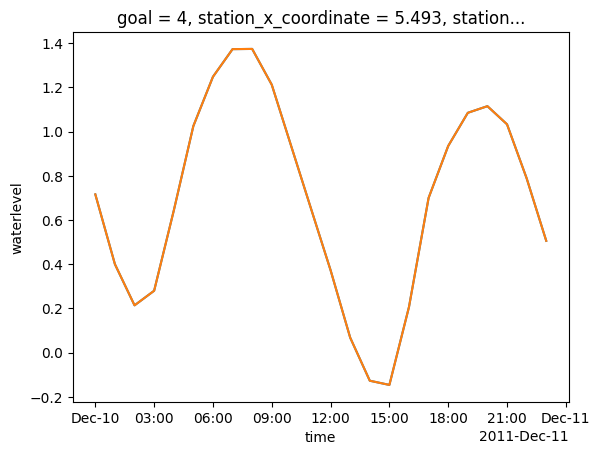

In [4]:
import xarray as xr

xr.open_dataset(
    "https://geoocean.unican.es/thredds/dodsC/rawData/Copernicus/CODEC/twl/reanalysis_waterlevel_hourly_2011_12_v1.nc"
).sel(stations=23599, time="2011-12-10").waterlevel.plot()
xr.open_zarr("inputs/CODEC/processed/CODEC_netherlands.zarr").sel(
    goal=4, time="2011-12-10"
).waterlevel.plot(hue="goal")

In [4]:
codec = xr.Dataset(
    {
        "waterlevel": (
            ("time", "goal"),
            xr.open_zarr(
                "inputs/CODEC/processed/OLD_CODEC_netherlands.zarr"
            ).waterlevel.values,
        ),
    },
    coords={
        "time": xr.open_zarr(
            "inputs/CODEC/processed/OLD_CODEC_netherlands.zarr"
        ).time.values,
        "goal": range(1, 11),
    },
)
codec = codec.assign_coords(
    {
        "stations": (
            ("goal"),
            xr.open_zarr(
                "inputs/CODEC/processed/OLD_CODEC_netherlands.zarr"
            ).stations.values,
        ),
        "station_x_coordinate": (
            ("goal"),
            xr.open_zarr(
                "inputs/CODEC/processed/OLD_CODEC_netherlands.zarr"
            ).station_x_coordinate.values,
        ),
        "station_y_coordinate": (
            ("goal"),
            xr.open_zarr(
                "inputs/CODEC/processed/OLD_CODEC_netherlands.zarr"
            ).station_y_coordinate.values,
        ),
    }
).sortby("goal")
codec

<xarray.Dataset> Size: 31MB
Dimensions:               (time: 350640, goal: 10)
Coordinates:
  * time                  (time) datetime64[ns] 3MB 1979-01-01 ... 2018-12-31...
  * goal                  (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    stations              (goal) int16 20B 23778 23711 23651 ... 23190 23125
    station_x_coordinate  (goal) float64 80B 6.987 6.489 5.991 ... 3.003 2.498
    station_y_coordinate  (goal) float64 80B 54.01 54.01 54.01 ... 51.99 51.49
Data variables:
    waterlevel            (time, goal) float64 28MB 0.067 0.062 ... 0.325 -0.146

In [5]:
codec.to_zarr("inputs/CODEC/processed/CODEC_netherlands.zarr")

/home/tausiaj/miniforge3/envs/bluemath-311-dev/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [1]:
import xarray as xr

for station in [23778, 23711, 23651, 23599, 23541, 23462, 23369, 23269, 23190, 23125]:
    codec = (
        xr.open_dataset(
            "https://geoocean.unican.es/thredds/dodsC/aggregatedDatasets/CODEC.nc"
        )
        .sel(stations=station)
        .chunk({"time": 365 * 24})
        .load()
    )
    codec.to_netcdf(f"inputs/CODEC/CODEC_{station}.nc")

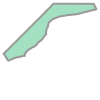

In [1]:
import alphashape
import numpy as np
import xarray as xr

mesh_nc = xr.open_dataset("inputs/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.nc")
ocean_region = alphashape.alphashape(
    np.column_stack([mesh_nc.mesh2d_node_x.values, mesh_nc.mesh2d_node_y.values])[
        ::5, :
    ],
    10,
)
ocean_region

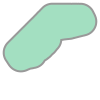

In [6]:
ocean_region = ocean_region.buffer(1)
ocean_region

In [11]:
import xarray as xr

codec_stations = xr.open_dataset(
    "https://geoocean.unican.es/thredds/dodsC/aggregatedDatasets/CODEC.nc"
)[["station_x_coordinate", "station_y_coordinate"]].load()
codec_stations

<xarray.Dataset> Size: 776kB
Dimensions:               (stations: 43119)
Coordinates:
  * stations              (stations) int16 86kB 0 1 2 3 ... -21805 -21804 -21803
    station_x_coordinate  (stations) float64 345kB 24.09 24.09 ... 37.75 37.95
    station_y_coordinate  (stations) float64 345kB 34.83 34.87 ... -46.98 -46.63
Data variables:
    *empty*
Attributes: (12/35)
    Conventions:                   CF-1.6
    featureType:                   timeSeries
    id:                            GTSMv3_surge
    naming_authority:              https://deltares.nl/en
    Metadata_Conventions:          Unidata Dataset Discovery v1.0
    title:                         CODEC
    ...                            ...
    time_coverage_start:           2018-11-01 00:00:00
    time_coverage_end:             2018-11-30 23:00:00
    experiment:                    reanalysis
    date_modified:                 2021-05-06 19:47:58.279267 UTC
    contact:                       Please contact Copernicus User Support on ...
    history:                       Created on 2024-12-08

In [7]:
from shapely.geometry import Point

interest_locations = []

for i, (codec_station_x, codec_station_y) in enumerate(
    zip(
        codec_stations.station_x_coordinate.values,
        codec_stations.station_y_coordinate.values,
    )
):
    if Point(codec_station_x, codec_station_y).within(ocean_region):
        interest_locations.append(i)

In [8]:
len(interest_locations)

407

In [ ]:
# codec_stations = codec_stations.isel(stations=interest_locations)
# codec_stations

In [12]:
codec_stations = codec_stations.sel(
    stations=[23778, 23711, 23651, 23599, 23541, 23462, 23369, 23269, 23190, 23125]
)
codec_stations

<xarray.Dataset> Size: 180B
Dimensions:               (stations: 10)
Coordinates:
  * stations              (stations) int16 20B 23778 23711 23651 ... 23190 23125
    station_x_coordinate  (stations) float64 80B 6.987 6.489 ... 3.003 2.498
    station_y_coordinate  (stations) float64 80B 54.01 54.01 ... 51.99 51.49
Data variables:
    *empty*
Attributes: (12/35)
    Conventions:                   CF-1.6
    featureType:                   timeSeries
    id:                            GTSMv3_surge
    naming_authority:              https://deltares.nl/en
    Metadata_Conventions:          Unidata Dataset Discovery v1.0
    title:                         CODEC
    ...                            ...
    time_coverage_start:           2018-11-01 00:00:00
    time_coverage_end:             2018-11-30 23:00:00
    experiment:                    reanalysis
    date_modified:                 2021-05-06 19:47:58.279267 UTC
    contact:                       Please contact Copernicus User Support on ...
    history:                       Created on 2024-12-08

In [ ]:
# check consistency with
# https://geoocean.unican.es/thredds/dodsC/rawData/Copernicus/CODEC/twl/
# reanalysis_waterlevel_hourly_1997_09_v1.nc.html

In [13]:
# Write station_x and y into txt file
with open("codec_stations.txt", "w") as f:
    for station_id, codec_station_x, codec_station_y in zip(
        codec_stations.stations.values,
        codec_stations.station_x_coordinate.values,
        codec_stations.station_y_coordinate.values,
    ):
        f.write(f"{station_id} {codec_station_x} {codec_station_y}\n")

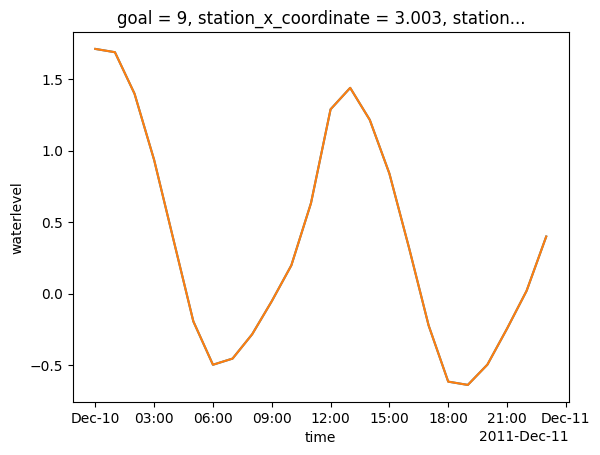

In [1]:
import xarray as xr

xr.open_dataset(
    "https://geoocean.unican.es/thredds/dodsC/rawData/Copernicus/CODEC/twl/reanalysis_waterlevel_hourly_2011_12_v1.nc"
).sel(stations=23190, time="2011-12-10").waterlevel.plot()
xr.open_zarr("inputs/CODEC/processed/CODEC_netherlands.zarr").sel(
    goal=9, time="2011-12-10"
).waterlevel.plot(hue="goal")

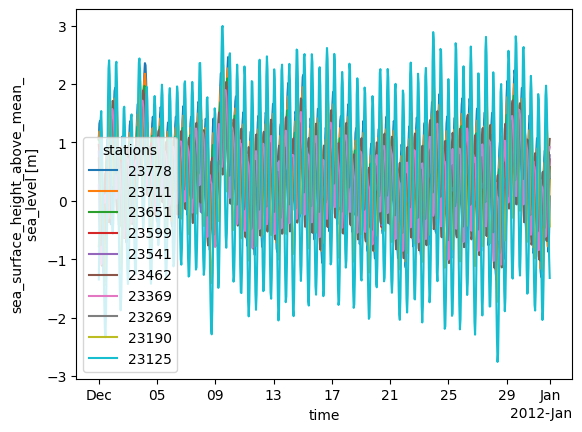

In [2]:
codec.waterlevel.plot(hue="stations")